In [4]:
#Plotting library
import matplotlib.pyplot as plt

#Data library...like Excel for python
import pandas as pd

#Numerical function library
import numpy as np

#Operating system, 'glob' library - for getting list of files in directory
import os, glob

#Jupyter command for generating Matplotlib plots inline with the commands in the notebook
%matplotlib inline


import seaborn as sns
import scipy
import math
from IPython.display import set_matplotlib_formats
# matplotlib_inline.backend_inline.set_matplotlib_formats()
set_matplotlib_formats('retina')

# plt.style.use('seaborn-whitegrid')

#set the working directory (where the data you want to work up is stored)
topwd='/Users/dcollins/Library/CloudStorage/OneDrive-NLR/20260806-3TT_TEST'

#change whatever the current working space is to the desired space, just set above
os.chdir(topwd)

#check that directory is right
os.getcwd()

/var/folders/v7/gxvkh6fs2bl1s2vfh9653l900000gr/T/ipykernel_8431/695485469.py:22: DeprecationWarning: `set_matplotlib_formats` is deprecated since IPython 7.23, directly use `matplotlib_inline.backend_inline.set_matplotlib_formats()`
  set_matplotlib_formats('retina')


'/Users/dcollins/Library/CloudStorage/OneDrive-NLR/20260806-3TT_TEST'

In [5]:
# change font if you want
plt.rcParams['font.sans-serif'] = "Arial"
plt.rcParams['font.family'] = "sans-serif"

In [4]:
#glob will find anything with string given and put it into filelist
filelist = sorted(glob.glob('*.mpt'))
#filelist='20260723_3Tagsd200nmgrid_seedafter_RZ_CV_inital_C01.mpt', '20260723_3Tagsd200nmgrid_seedafter_RZ_ce_ccloth2_re_agagclleakless_10mlmin_1sun_after_cp1_cv1_C01.mpt', '20260723_3Tagsd200nmgrid_seedafter_RZ_ce_ccloth2_re_agagclleakless_10mlmin_dark_after_cp2_cv2_C01.mpt',
filelist

['20260806_3ttUN_FZ_dry_1sun_CV_C01.mpt',
 '20260806_3ttUN_TR_dry_1sun_CV_C01.mpt',
 '20260806_MW736n1_RZ_dry_1sun_CV_C01.mpt',
 '20260806_MW736n1_TR_dry_1sun_CV_C01.mpt',
 '20260806_MW736n1_TZ_dry_1sun_CV_C01.mpt',
 '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p1sun_2_C01.mpt',
 '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p1sun_2_C02.mpt',
 '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p1sun_C01.mpt',
 '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p1sun_C02.mpt',
 '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p5sun_C01.mpt',
 '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p5sun_C02.mpt',
 '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_1sun_C01.mpt',
 '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_1sun_C02.mpt',
 '20260806_MW736n2_RZ_dry_1sun_CV_C01.mpt',
 '20260806_MW736n2_TR_dry_1sun_CV_C01.mpt',
 '20260806_MW736n2_Tz_dry_1sun_CV_C01.mpt']

In [5]:
#glob will find anything with string given and put it into filelist
filelist = sorted(glob.glob('*cp9*.mpt'))
filelist = '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p1sun_2_C01.mpt', '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p5sun_C01.mpt', '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_1sun_C01.mpt',


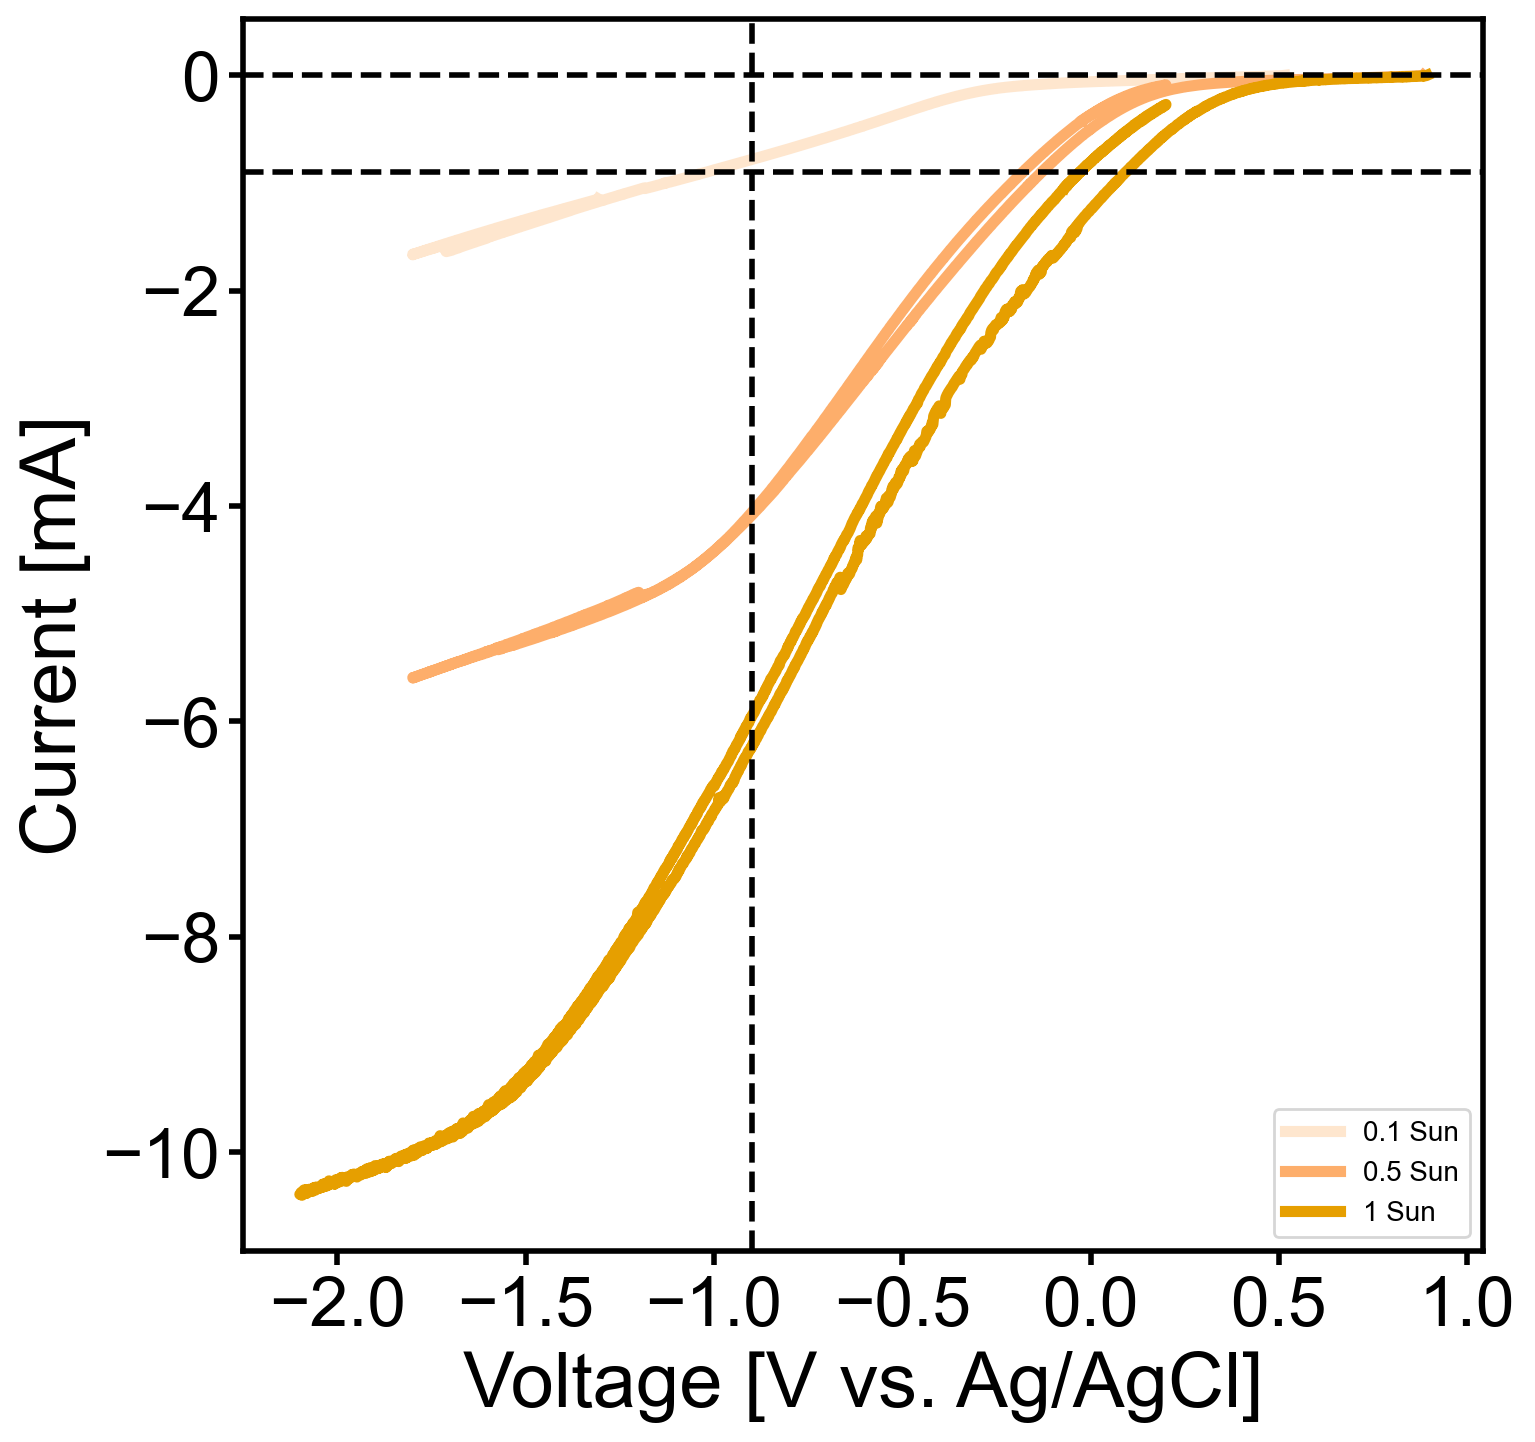

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Define your files and plot properties
filelist = [
    '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p1sun_2_C01.mpt',
    '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p5sun_C01.mpt',
    '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_1sun_C01.mpt'
]
labels = ['0.1 Sun', '0.5 Sun', '1 Sun']
colors = ['#1D4499', "#1f77b4", "#2ca02c"]
colors = ['#FEE6CE','#FDAE6B','#E69F00']

# Set up the static figure
plt.figure(figsize=(8, 8))

# Function to dynamically find the correct data starting row in each file
def find_header_line_number(filepath, encoding='ISO-8859-1'):
    try:
        with open(filepath, 'r', encoding=encoding) as f:
            for i, line in enumerate(f):
                if 'Ewe/V' in line and '<I>/mA' in line:
                    return i
    except FileNotFoundError:
        return -2
    return -1

# 2. Loop and plot each file
for jj, filename in enumerate(filelist):
    header_row_index = find_header_line_number(filename)
    
    if header_row_index == -2:
        print(f"Error: The file '{filename}' was not found. Please restore it to this folder.")
        continue
    if header_row_index == -1:
        print(f"Warning: Could not find header 'Ewe/V' in '{filename}'. Skipping.")
        continue
        
    try:
        # Read the file using ISO-8859-1 encoding to prevent decoding errors
        df = pd.read_csv(filename, skiprows=header_row_index, delimiter='\t', engine='python', encoding='ISO-8859-1')
        
        # Plot the static line
        plt.plot(df['Ewe/V'], df['<I>/mA'], color=colors[jj], linewidth=4.0)
        
    except Exception as e:
        print(f"An error occurred while reading '{filename}': {e}")

# --- 3. Plot Configurations ---
plt.xlabel('Voltage [V vs. Ag/AgCl]', fontsize=28) 
plt.ylabel('Current [mA]', fontsize=28)
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)
plt.tick_params(axis='both', width=2, length=5)
plt.legend(labels, loc="lower right")
#plt.axhline(y=-9, color='k', linestyle='--', linewidth=2)
plt.axhline(y=-0.9, color='k', linestyle='--', linewidth=2)
#plt.axhline(y=-1, color='k', linestyle='--', linewidth=2)
#plt.axvline(x=-1.4, color='k', linestyle='--', linewidth=2)
plt.axhline(y=0, color='k', linestyle='--', linewidth=2)
plt.axvline(x=-.9, color='k', linestyle='--', linewidth=2)

# Adjust plot boundaries to match your original design
ax = plt.gca()
ax.spines['right'].set_visible(True)
ax.spines['top'].set_visible(True)
ax.spines['left'].set_color('k')
ax.spines['left'].set_linewidth(2)
ax.spines['top'].set_color('k')
ax.spines['top'].set_linewidth(2)
ax.spines['right'].set_color('k')
ax.spines['right'].set_linewidth(2)
ax.spines['bottom'].set_color('k')
ax.spines['bottom'].set_linewidth(2)

plt.show()


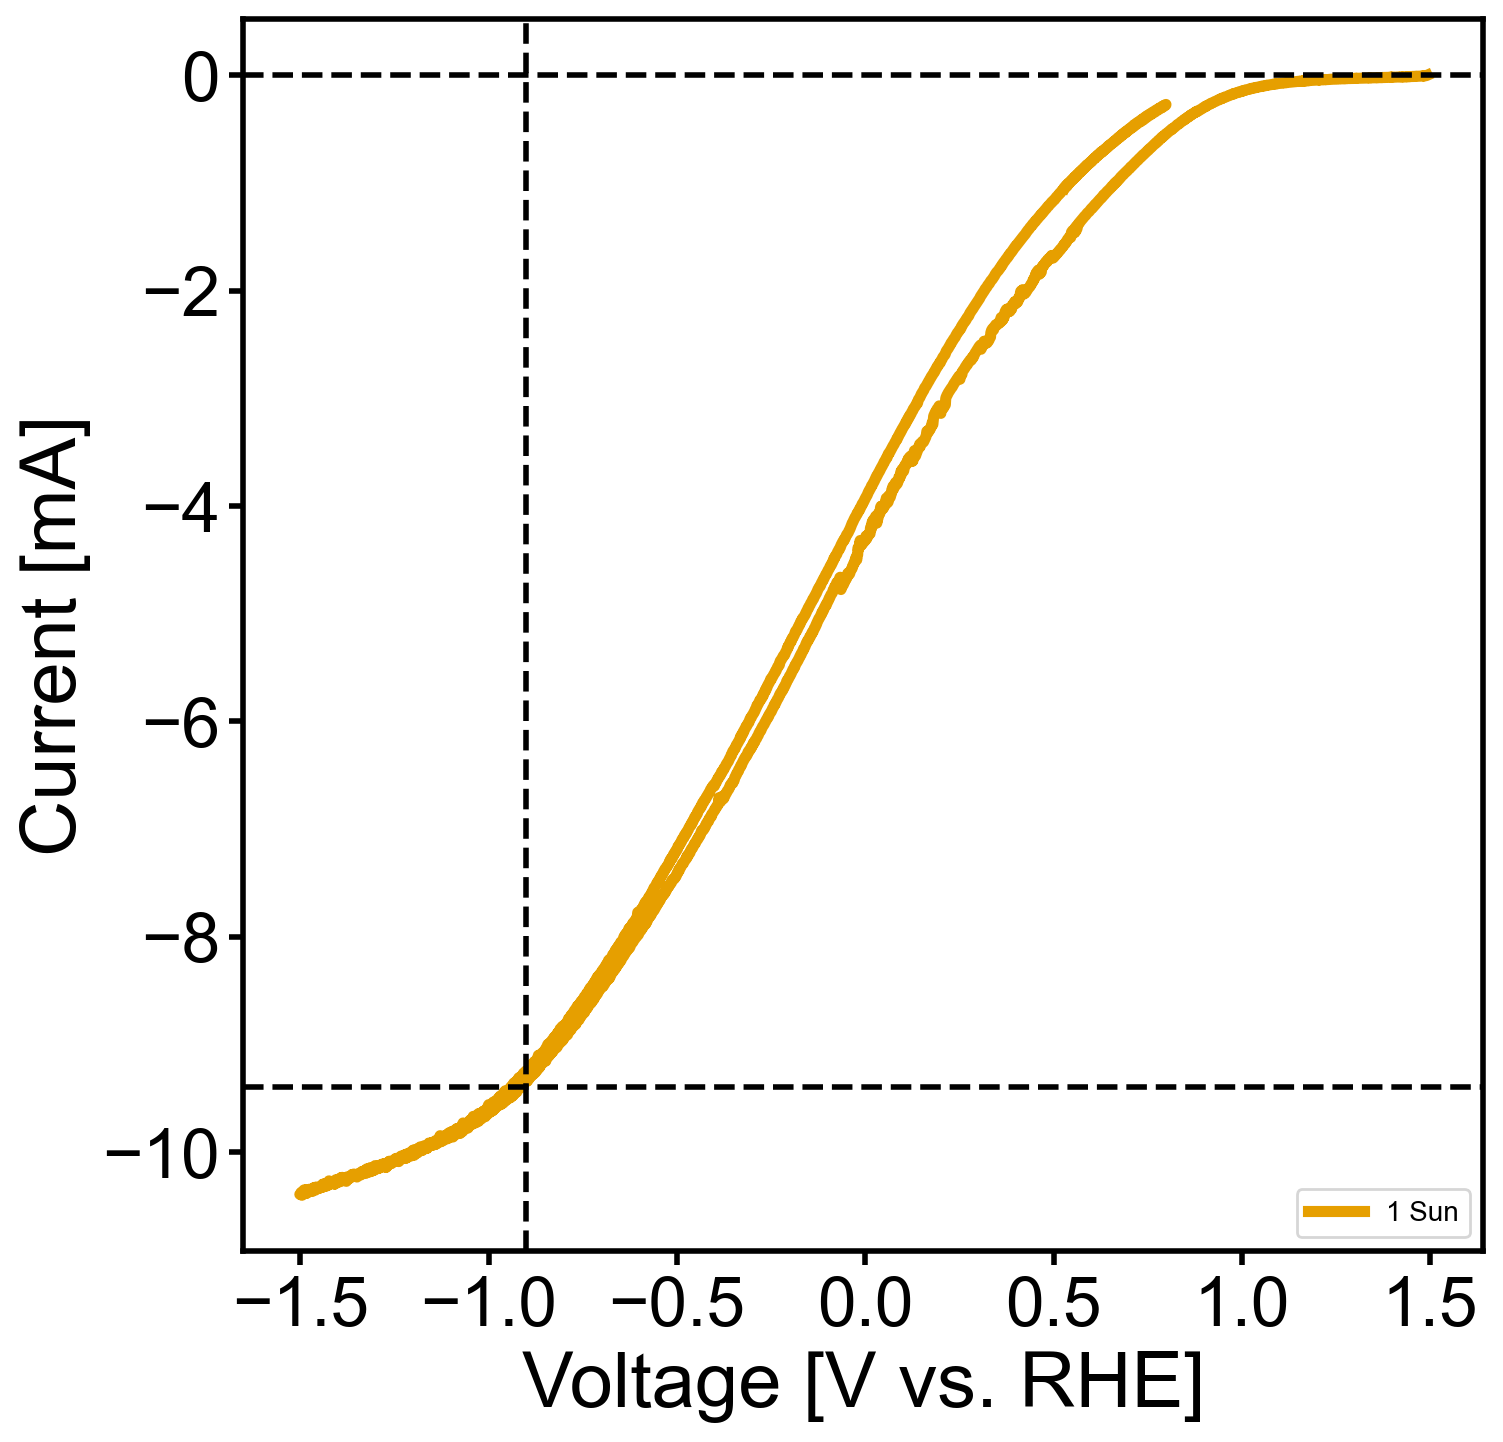

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Define your files and plot properties
filelist = [
    '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_1sun_C01.mpt'
]
labels = [ '1 Sun']
colors = ['#1D4499', "#1f77b4", "#2ca02c"]
colors = ['#E69F00']

ref = 0.197
pH = 6.8
refi = ref + 0.059 * pH
# Set up the static figure
plt.figure(figsize=(8, 8))

# Function to dynamically find the correct data starting row in each file
def find_header_line_number(filepath, encoding='ISO-8859-1'):
    try:
        with open(filepath, 'r', encoding=encoding) as f:
            for i, line in enumerate(f):
                if 'Ewe/V' in line and '<I>/mA' in line:
                    return i
    except FileNotFoundError:
        return -2
    return -1

# 2. Loop and plot each file
for jj, filename in enumerate(filelist):
    header_row_index = find_header_line_number(filename)
    
    if header_row_index == -2:
        print(f"Error: The file '{filename}' was not found. Please restore it to this folder.")
        continue
    if header_row_index == -1:
        print(f"Warning: Could not find header 'Ewe/V' in '{filename}'. Skipping.")
        continue
        
    try:
        # Read the file using ISO-8859-1 encoding to prevent decoding errors
        df = pd.read_csv(filename, skiprows=header_row_index, delimiter='\t', engine='python', encoding='ISO-8859-1')
        
        # Plot the static line
        plt.plot(df['Ewe/V']+refi, df['<I>/mA'], color=colors[jj], linewidth=4.0)
        
    except Exception as e:
        print(f"An error occurred while reading '{filename}': {e}")

# --- 3. Plot Configurations ---
plt.xlabel('Voltage [V vs. RHE]', fontsize=28) 
plt.ylabel('Current [mA]', fontsize=28)
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)
plt.tick_params(axis='both', width=2, length=5)
plt.legend(labels, loc="lower right")
#plt.axhline(y=-9, color='k', linestyle='--', linewidth=2)
plt.axhline(y=-9.4, color='k', linestyle='--', linewidth=2)
#plt.axhline(y=-1, color='k', linestyle='--', linewidth=2)
#plt.axvline(x=-1.4, color='k', linestyle='--', linewidth=2)
plt.axhline(y=0, color='k', linestyle='--', linewidth=2)
plt.axvline(x=-0.9, color='k', linestyle='--', linewidth=2)

# Adjust plot boundaries to match your original design
ax = plt.gca()
ax.spines['right'].set_visible(True)
ax.spines['top'].set_visible(True)
ax.spines['left'].set_color('k')
ax.spines['left'].set_linewidth(2)
ax.spines['top'].set_color('k')
ax.spines['top'].set_linewidth(2)
ax.spines['right'].set_color('k')
ax.spines['right'].set_linewidth(2)
ax.spines['bottom'].set_color('k')
ax.spines['bottom'].set_linewidth(2)

plt.show()

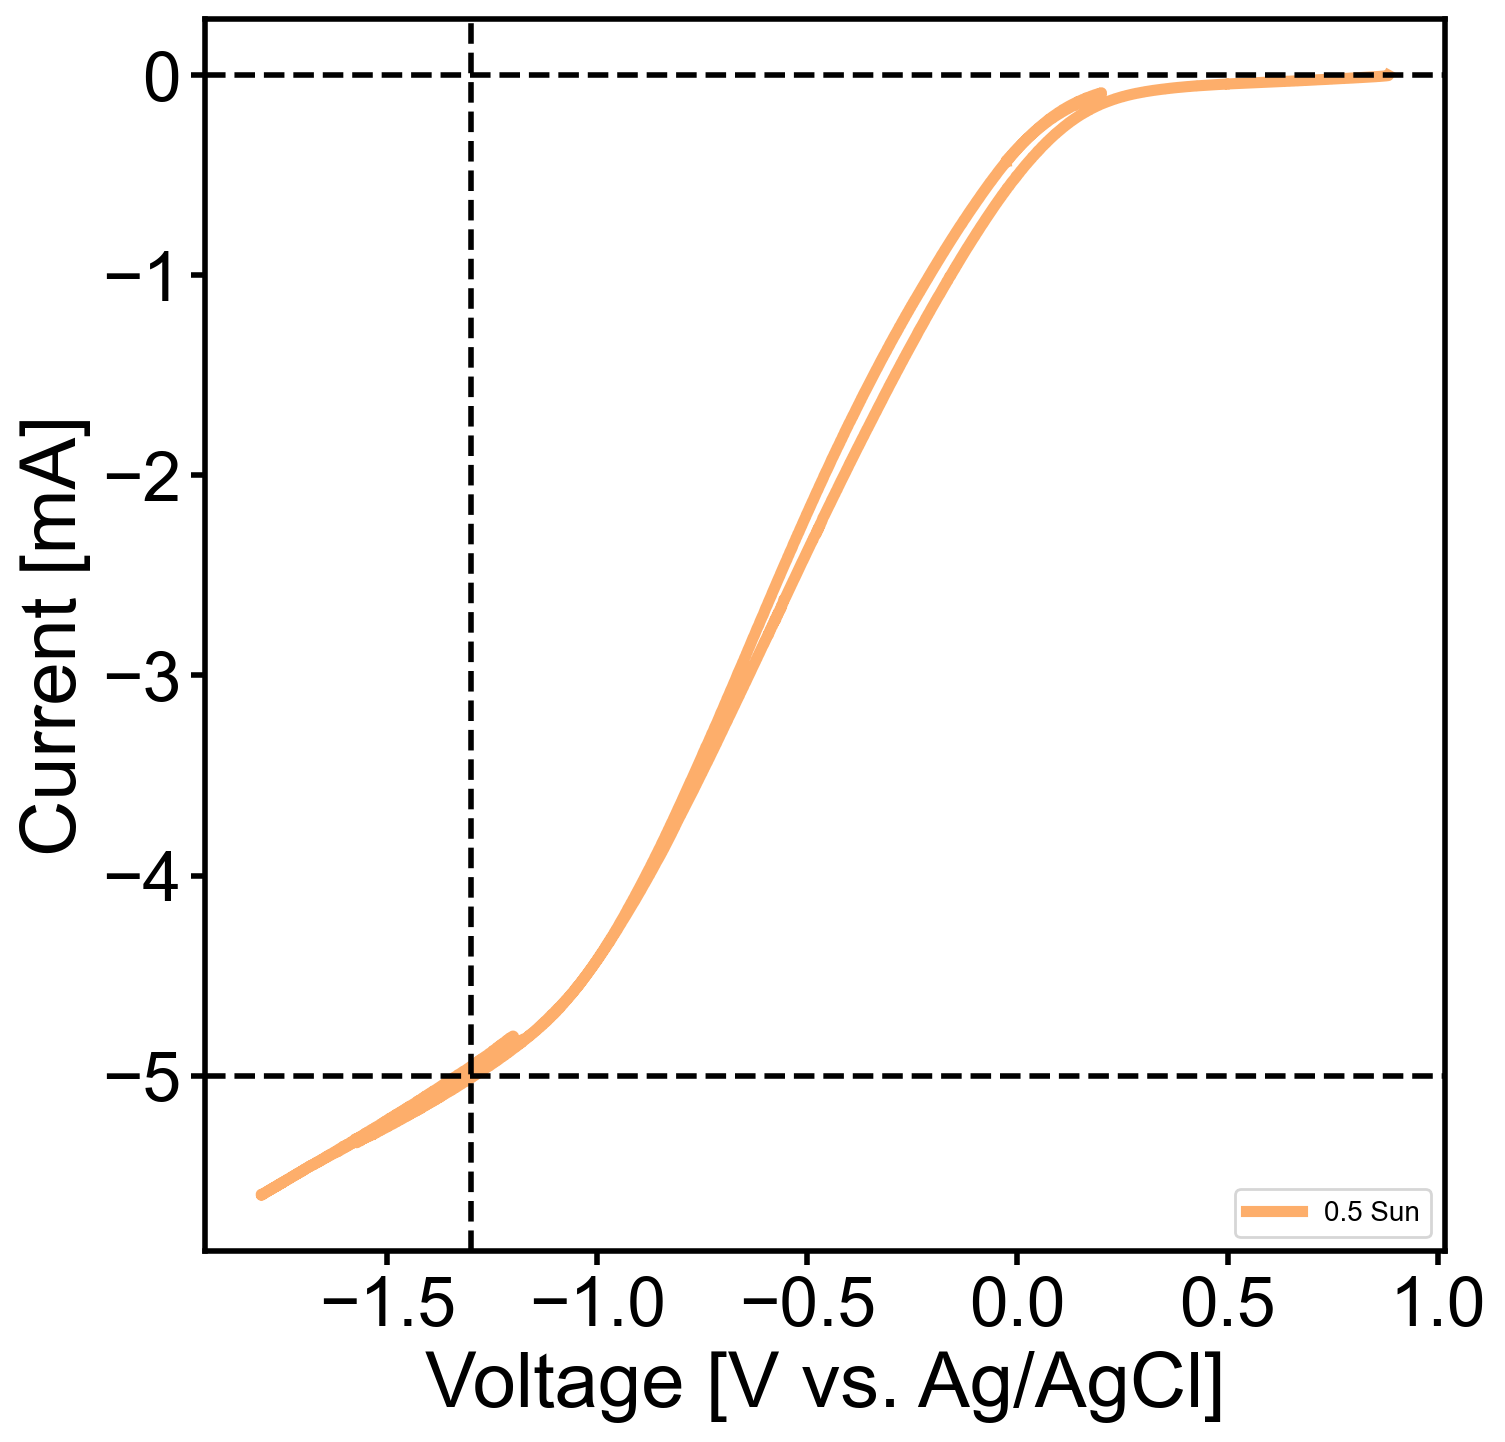

In [34]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Define your files and plot properties
filelist = [
   '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p5sun_C01.mpt',
]
labels = [ '0.5 Sun']
colors = ['#FDAE6B',]
##colors = ['#E69F00']

# Set up the static figure
plt.figure(figsize=(8, 8))

# Function to dynamically find the correct data starting row in each file
def find_header_line_number(filepath, encoding='ISO-8859-1'):
    try:
        with open(filepath, 'r', encoding=encoding) as f:
            for i, line in enumerate(f):
                if 'Ewe/V' in line and '<I>/mA' in line:
                    return i
    except FileNotFoundError:
        return -2
    return -1

# 2. Loop and plot each file
for jj, filename in enumerate(filelist):
    header_row_index = find_header_line_number(filename)
    
    if header_row_index == -2:
        print(f"Error: The file '{filename}' was not found. Please restore it to this folder.")
        continue
    if header_row_index == -1:
        print(f"Warning: Could not find header 'Ewe/V' in '{filename}'. Skipping.")
        continue
        
    try:
        # Read the file using ISO-8859-1 encoding to prevent decoding errors
        df = pd.read_csv(filename, skiprows=header_row_index, delimiter='\t', engine='python', encoding='ISO-8859-1')
        
        # Plot the static line
        plt.plot(df['Ewe/V'], df['<I>/mA'], color=colors[jj], linewidth=4.0)
        
    except Exception as e:
        print(f"An error occurred while reading '{filename}': {e}")

# --- 3. Plot Configurations ---
plt.xlabel('Voltage [V vs. Ag/AgCl]', fontsize=28) 
plt.ylabel('Current [mA]', fontsize=28)
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)
plt.tick_params(axis='both', width=2, length=5)
plt.legend(labels, loc="lower right")
#plt.axhline(y=-9, color='k', linestyle='--', linewidth=2)
plt.axhline(y=-5, color='k', linestyle='--', linewidth=2)
#plt.axhline(y=-1, color='k', linestyle='--', linewidth=2)
#plt.axvline(x=-1.4, color='k', linestyle='--', linewidth=2)
plt.axhline(y=0, color='k', linestyle='--', linewidth=2)
plt.axvline(x=-1.3, color='k', linestyle='--', linewidth=2)

# Adjust plot boundaries to match your original design
ax = plt.gca()
ax.spines['right'].set_visible(True)
ax.spines['top'].set_visible(True)
ax.spines['left'].set_color('k')
ax.spines['left'].set_linewidth(2)
ax.spines['top'].set_color('k')
ax.spines['top'].set_linewidth(2)
ax.spines['right'].set_color('k')
ax.spines['right'].set_linewidth(2)
ax.spines['bottom'].set_color('k')
ax.spines['bottom'].set_linewidth(2)

plt.show()

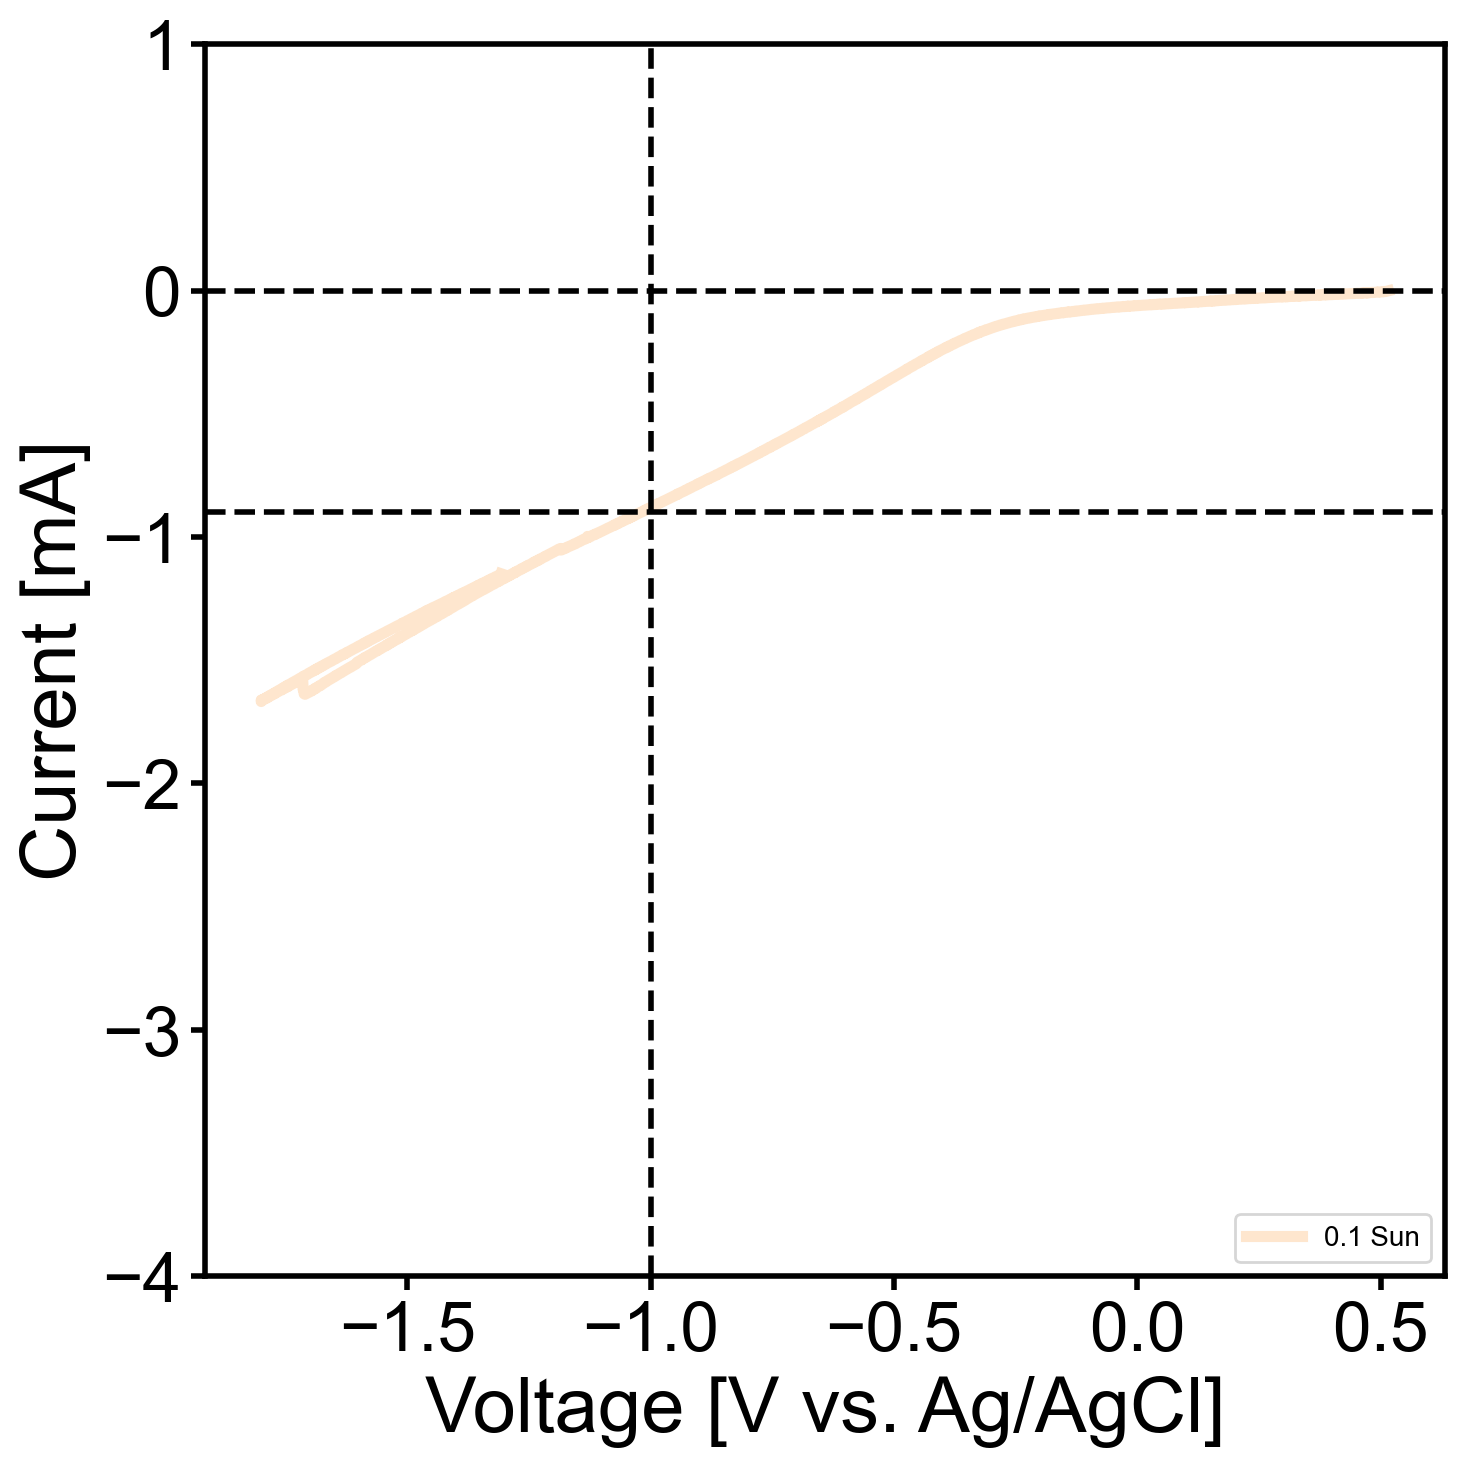

In [32]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Define your files and plot properties
filelist = [
    '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p1sun_2_C01.mpt',
]
labels = [ '0.1 Sun']
colors = ['#FEE6CE',]
##colors = ['#E69F00']

# Set up the static figure
plt.figure(figsize=(8, 8))

# Function to dynamically find the correct data starting row in each file
def find_header_line_number(filepath, encoding='ISO-8859-1'):
    try:
        with open(filepath, 'r', encoding=encoding) as f:
            for i, line in enumerate(f):
                if 'Ewe/V' in line and '<I>/mA' in line:
                    return i
    except FileNotFoundError:
        return -2
    return -1

# 2. Loop and plot each file
for jj, filename in enumerate(filelist):
    header_row_index = find_header_line_number(filename)
    
    if header_row_index == -2:
        print(f"Error: The file '{filename}' was not found. Please restore it to this folder.")
        continue
    if header_row_index == -1:
        print(f"Warning: Could not find header 'Ewe/V' in '{filename}'. Skipping.")
        continue
        
    try:
        # Read the file using ISO-8859-1 encoding to prevent decoding errors
        df = pd.read_csv(filename, skiprows=header_row_index, delimiter='\t', engine='python', encoding='ISO-8859-1')
        
        # Plot the static line
        plt.plot(df['Ewe/V'], df['<I>/mA'], color=colors[jj], linewidth=4.0)
        
    except Exception as e:
        print(f"An error occurred while reading '{filename}': {e}")

# --- 3. Plot Configurations ---
plt.xlabel('Voltage [V vs. Ag/AgCl]', fontsize=28) 
plt.ylabel('Current [mA]', fontsize=28)
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)
plt.tick_params(axis='both', width=2, length=5)
plt.legend(labels, loc="lower right")
#plt.axhline(y=-9, color='k', linestyle='--', linewidth=2)
plt.axhline(y=-0.9, color='k', linestyle='--', linewidth=2)
#plt.axhline(y=-1, color='k', linestyle='--', linewidth=2)
#plt.axvline(x=-1.4, color='k', linestyle='--', linewidth=2)
plt.axhline(y=0, color='k', linestyle='--', linewidth=2)
plt.axvline(x=-1, color='k', linestyle='--', linewidth=2)
plt.ylim(-4,1)

# Adjust plot boundaries to match your original design
ax = plt.gca()
ax.spines['right'].set_visible(True)
ax.spines['top'].set_visible(True)
ax.spines['left'].set_color('k')
ax.spines['left'].set_linewidth(2)
ax.spines['top'].set_color('k')
ax.spines['top'].set_linewidth(2)
ax.spines['right'].set_color('k')
ax.spines['right'].set_linewidth(2)
ax.spines['bottom'].set_color('k')
ax.spines['bottom'].set_linewidth(2)

plt.show()

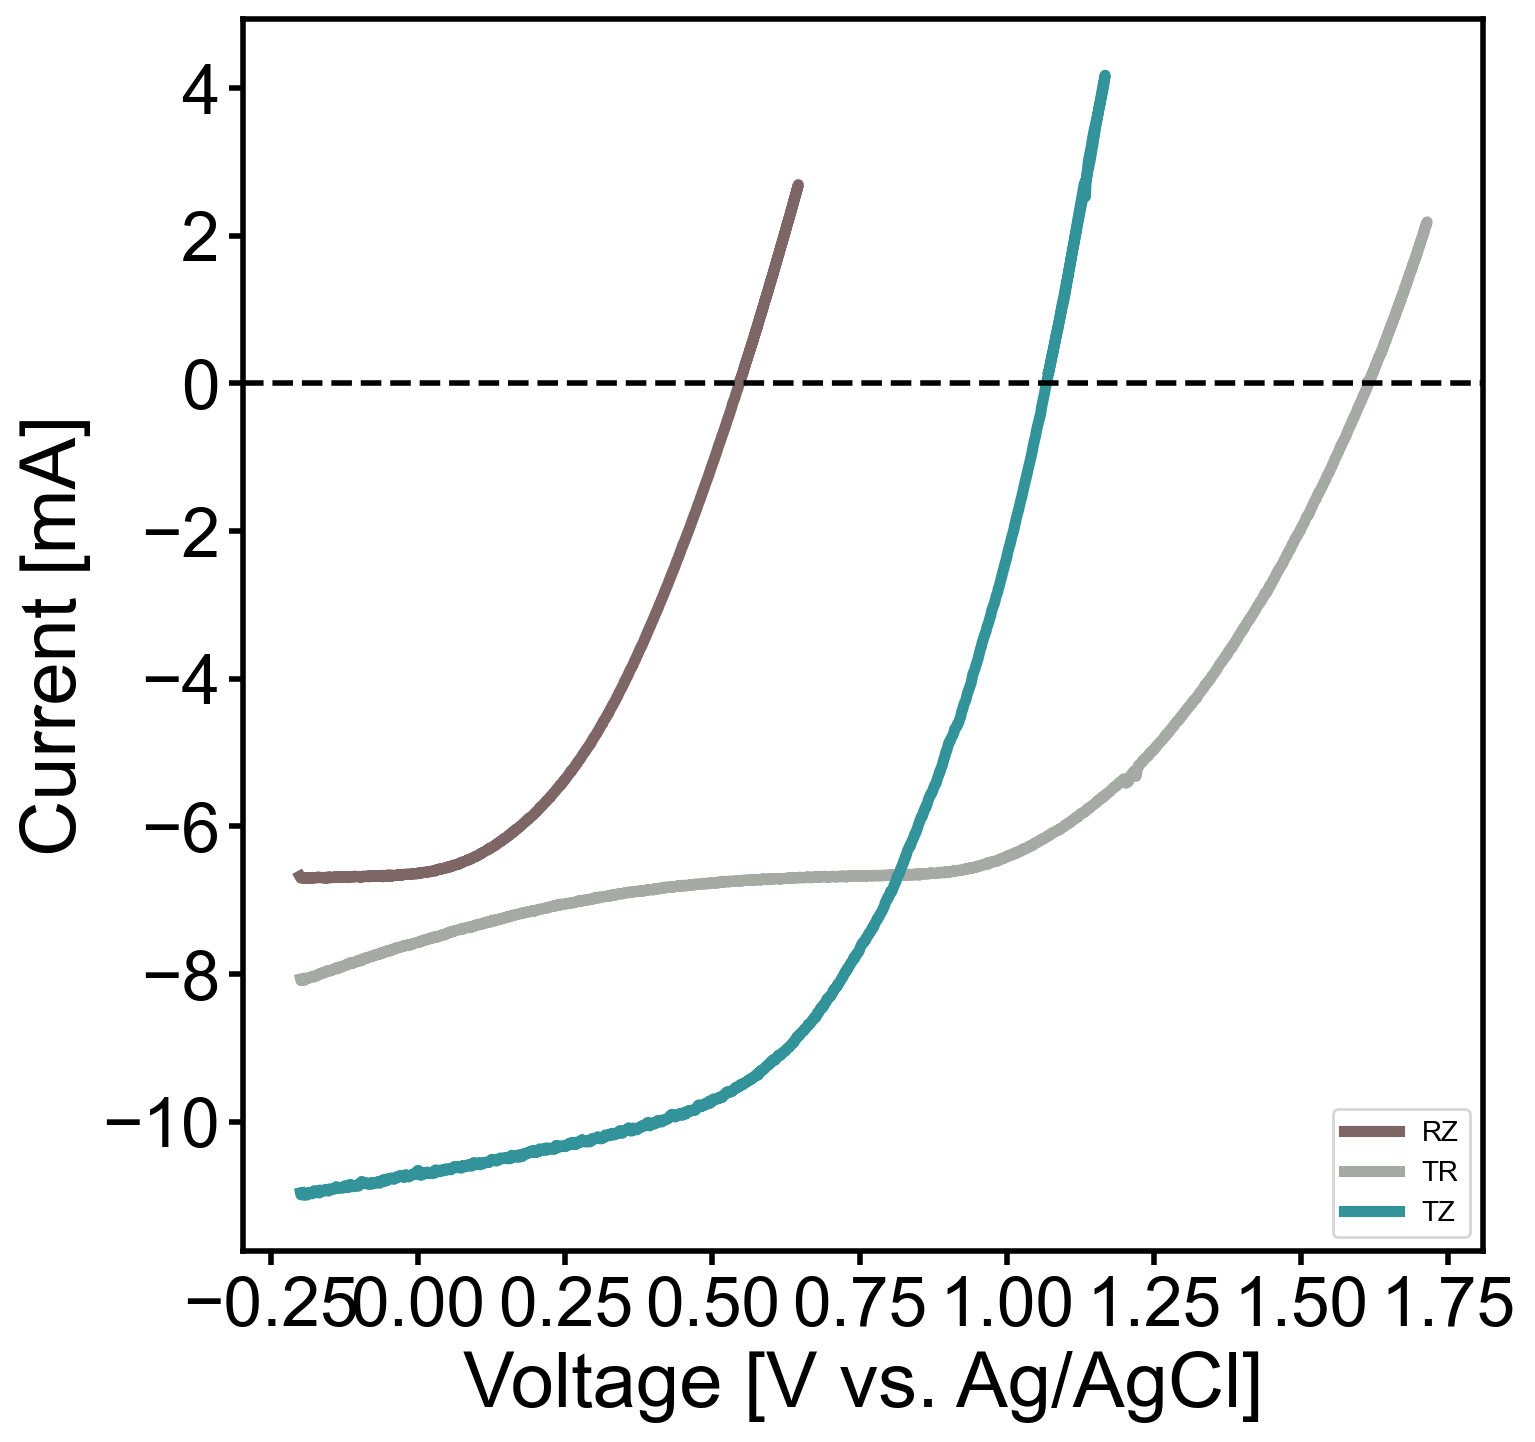

In [42]:



import pandas as pd
import matplotlib.pyplot as plt

# 1. Define your files and plot properties
filelist = [
 '20260806_MW736n1_RZ_dry_1sun_CV_C01.mpt',
 '20260806_MW736n1_TR_dry_1sun_CV_C01.mpt',
 '20260806_MW736n1_TZ_dry_1sun_CV_C01.mpt',
]
labels = ['RZ', 'TR', 'TZ']
colors = ['#1D4499', "#1f77b4", "#2ca02c"]
colors = ['#7e6566', '#a6aaa4','#33939a']

# Set up the static figure
plt.figure(figsize=(8, 8))

# Function to dynamically find the correct data starting row in each file
def find_header_line_number(filepath, encoding='ISO-8859-1'):
    try:
        with open(filepath, 'r', encoding=encoding) as f:
            for i, line in enumerate(f):
                if 'Ewe/V' in line and '<I>/mA' in line:
                    return i
    except FileNotFoundError:
        return -2
    return -1

# 2. Loop and plot each file
for jj, filename in enumerate(filelist):
    header_row_index = find_header_line_number(filename)
    
    if header_row_index == -2:
        print(f"Error: The file '{filename}' was not found. Please restore it to this folder.")
        continue
    if header_row_index == -1:
        print(f"Warning: Could not find header 'Ewe/V' in '{filename}'. Skipping.")
        continue
        
    try:
        # Read the file using ISO-8859-1 encoding to prevent decoding errors
        df = pd.read_csv(filename, skiprows=header_row_index, delimiter='\t', engine='python', encoding='ISO-8859-1')
        
        # Plot the static line
        plt.plot(df['Ewe/V'], df['<I>/mA'], color=colors[jj], linewidth=4.0)
        
    except Exception as e:
        print(f"An error occurred while reading '{filename}': {e}")

# --- 3. Plot Configurations ---
plt.xlabel('Voltage [V vs. Ag/AgCl]', fontsize=28) 
plt.ylabel('Current [mA]', fontsize=28)
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)
plt.tick_params(axis='both', width=2, length=5)
plt.legend(labels, loc="lower right")
#plt.axhline(y=-9, color='k', linestyle='--', linewidth=2)
#plt.axhline(y=-0.9, color='k', linestyle='--', linewidth=2)
#plt.axhline(y=-1, color='k', linestyle='--', linewidth=2)
#plt.axvline(x=-1.4, color='k', linestyle='--', linewidth=2)
plt.axhline(y=0, color='k', linestyle='--', linewidth=2)
#plt.axvline(x=-.9, color='k', linestyle='--', linewidth=2)

# Adjust plot boundaries to match your original design
ax = plt.gca()
ax.spines['right'].set_visible(True)
ax.spines['top'].set_visible(True)
ax.spines['left'].set_color('k')
ax.spines['left'].set_linewidth(2)
ax.spines['top'].set_color('k')
ax.spines['top'].set_linewidth(2)
ax.spines['right'].set_color('k')
ax.spines['right'].set_linewidth(2)
ax.spines['bottom'].set_color('k')
ax.spines['bottom'].set_linewidth(2)

plt.show()


In [5]:
filelist = sorted(glob.glob('*.mpt'))
#filelist='20260723_3Tagsd200nmgrid_seedafter_RZ_CV_inital_C01.mpt', '20260723_3Tagsd200nmgrid_seedafter_RZ_ce_ccloth2_re_agagclleakless_10mlmin_1sun_after_cp1_cv1_C01.mpt', '20260723_3Tagsd200nmgrid_seedafter_RZ_ce_ccloth2_re_agagclleakless_10mlmin_dark_after_cp2_cv2_C01.mpt',
filelist

['20260806_3ttUN_FZ_dry_1sun_CV_C01.mpt',
 '20260806_3ttUN_TR_dry_1sun_CV_C01.mpt',
 '20260806_MW736n1_RZ_dry_1sun_CV_C01.mpt',
 '20260806_MW736n1_TR_dry_1sun_CV_C01.mpt',
 '20260806_MW736n1_TZ_dry_1sun_CV_C01.mpt',
 '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p1sun_2_C01.mpt',
 '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p1sun_2_C02.mpt',
 '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p1sun_C01.mpt',
 '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p1sun_C02.mpt',
 '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p5sun_C01.mpt',
 '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p5sun_C02.mpt',
 '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_1sun_C01.mpt',
 '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_1sun_C02.mpt',
 '20260806_MW736n2_RZ_dry_1sun_CV_C01.mpt',
 '20260806_MW736n2_TR_dry_1sun_CV_C01.mpt',
 '20260806_MW736n2_Tz_dry_1sun_CV_C01.mpt']

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

filelist0p1sun = [
    '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p1sun_2_C01.mpt',
 '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p1sun_2_C02.mpt',
]
# ==========================================
# IMPORTANT NOTE:
# This script assumes that the variable `filelist_MV782n2_OCV` is a list
# of valid file paths that `pd.read_csv` can access in your local environment.
# ==========================================

# Make sure this variable is defined and points to your real files
# Example:
# filelist_MV782n2_OCV = ['path/to/file1.csv', 'path/to/file2.csv', ...]
VALID_VOLTAGE_MIN = -10.0
VALID_VOLTAGE_MAX = 2.0
plt.figure(figsize=(12, 8))
plt.grid(False)

# --- Constants & Setup ---
ref = 0.197
pH = 6.8
refi = ref + 0.059 * pH
cmap = ["#9467bd",'m', 'c', 'y', '#1f77b4', '#ff7f0e', '#2ca02c']
cmap = ["#dab6fc", "#757bc8"]
time_offset_hours = 0.0
plot_labels = ['initial FR','after 6hr in the dark FR', '3', '4', '5', '6', '7', '8', '9'
]

# --- Plotting Loop with Filtering ---
print(f"Filtering out data points outside the range: {VALID_VOLTAGE_MIN}V to {VALID_VOLTAGE_MAX}V")

for jj in range(len(filelist0p1sun)):
    skip = 70
    # 1. Read your actual data file
    df = pd.read_csv(filelist0p1sun[jj], skiprows=skip, encoding="ISO-8859-1", delimiter='\t')

    # 2. <<< NEW: Filter the DataFrame to remove outliers >>>
    df = df[(df['<Ewe/V>'] >= VALID_VOLTAGE_MIN) & (df['<Ewe/V>'] <= VALID_VOLTAGE_MAX)]


    current_label = plot_labels[jj] if jj < len(plot_labels) else f'File {jj}'
    plt.plot(df['time/s']/3600, df['<Ewe/V>'] + refi - 0.09, color=cmap[jj % len(cmap)], linewidth=2.0, label=current_label)

    # Update the offset for the next file based on the max time in the *cleaned* data
    if not current_time_hours.empty:
        time_offset_hours += current_time_hours.max()

# --- Formatting ---
plt.tick_params(axis='both', right=True, top=True, direction='in', width=2, length=5)
ax = plt.gca()
ax.spines['left'].set_linewidth(2)
ax.spines['top'].set_linewidth(2)
ax.spines['right'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)
plt.xlabel('Cumulative Time (hr)', fontsize=18)
plt.ylabel('Potential vs RHE (V)', fontsize=18)
plt.yticks(fontsize=18)
plt.xticks(fontsize=18)
#plt.legend()
plt.tight_layout()
plt.ylim(-0.65, -0.6)
plt.savefig("zoomed_voltage_after_ocv.pdf", format="pdf", bbox_inches="tight")

plt.show()



Filtering out data points outside the range: -10.0V to 2.0V


KeyError: '<Ewe/V>'

Filtering out data points outside the range: -10.0V to 2.0V
Reading file '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p1sun_2_C01.mpt', skipping 0 header lines.
An error occurred while processing '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p1sun_2_C01.mpt': Expected 1 fields in line 16, saw 2
Reading file '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p1sun_2_C02.mpt', skipping 48 header lines.


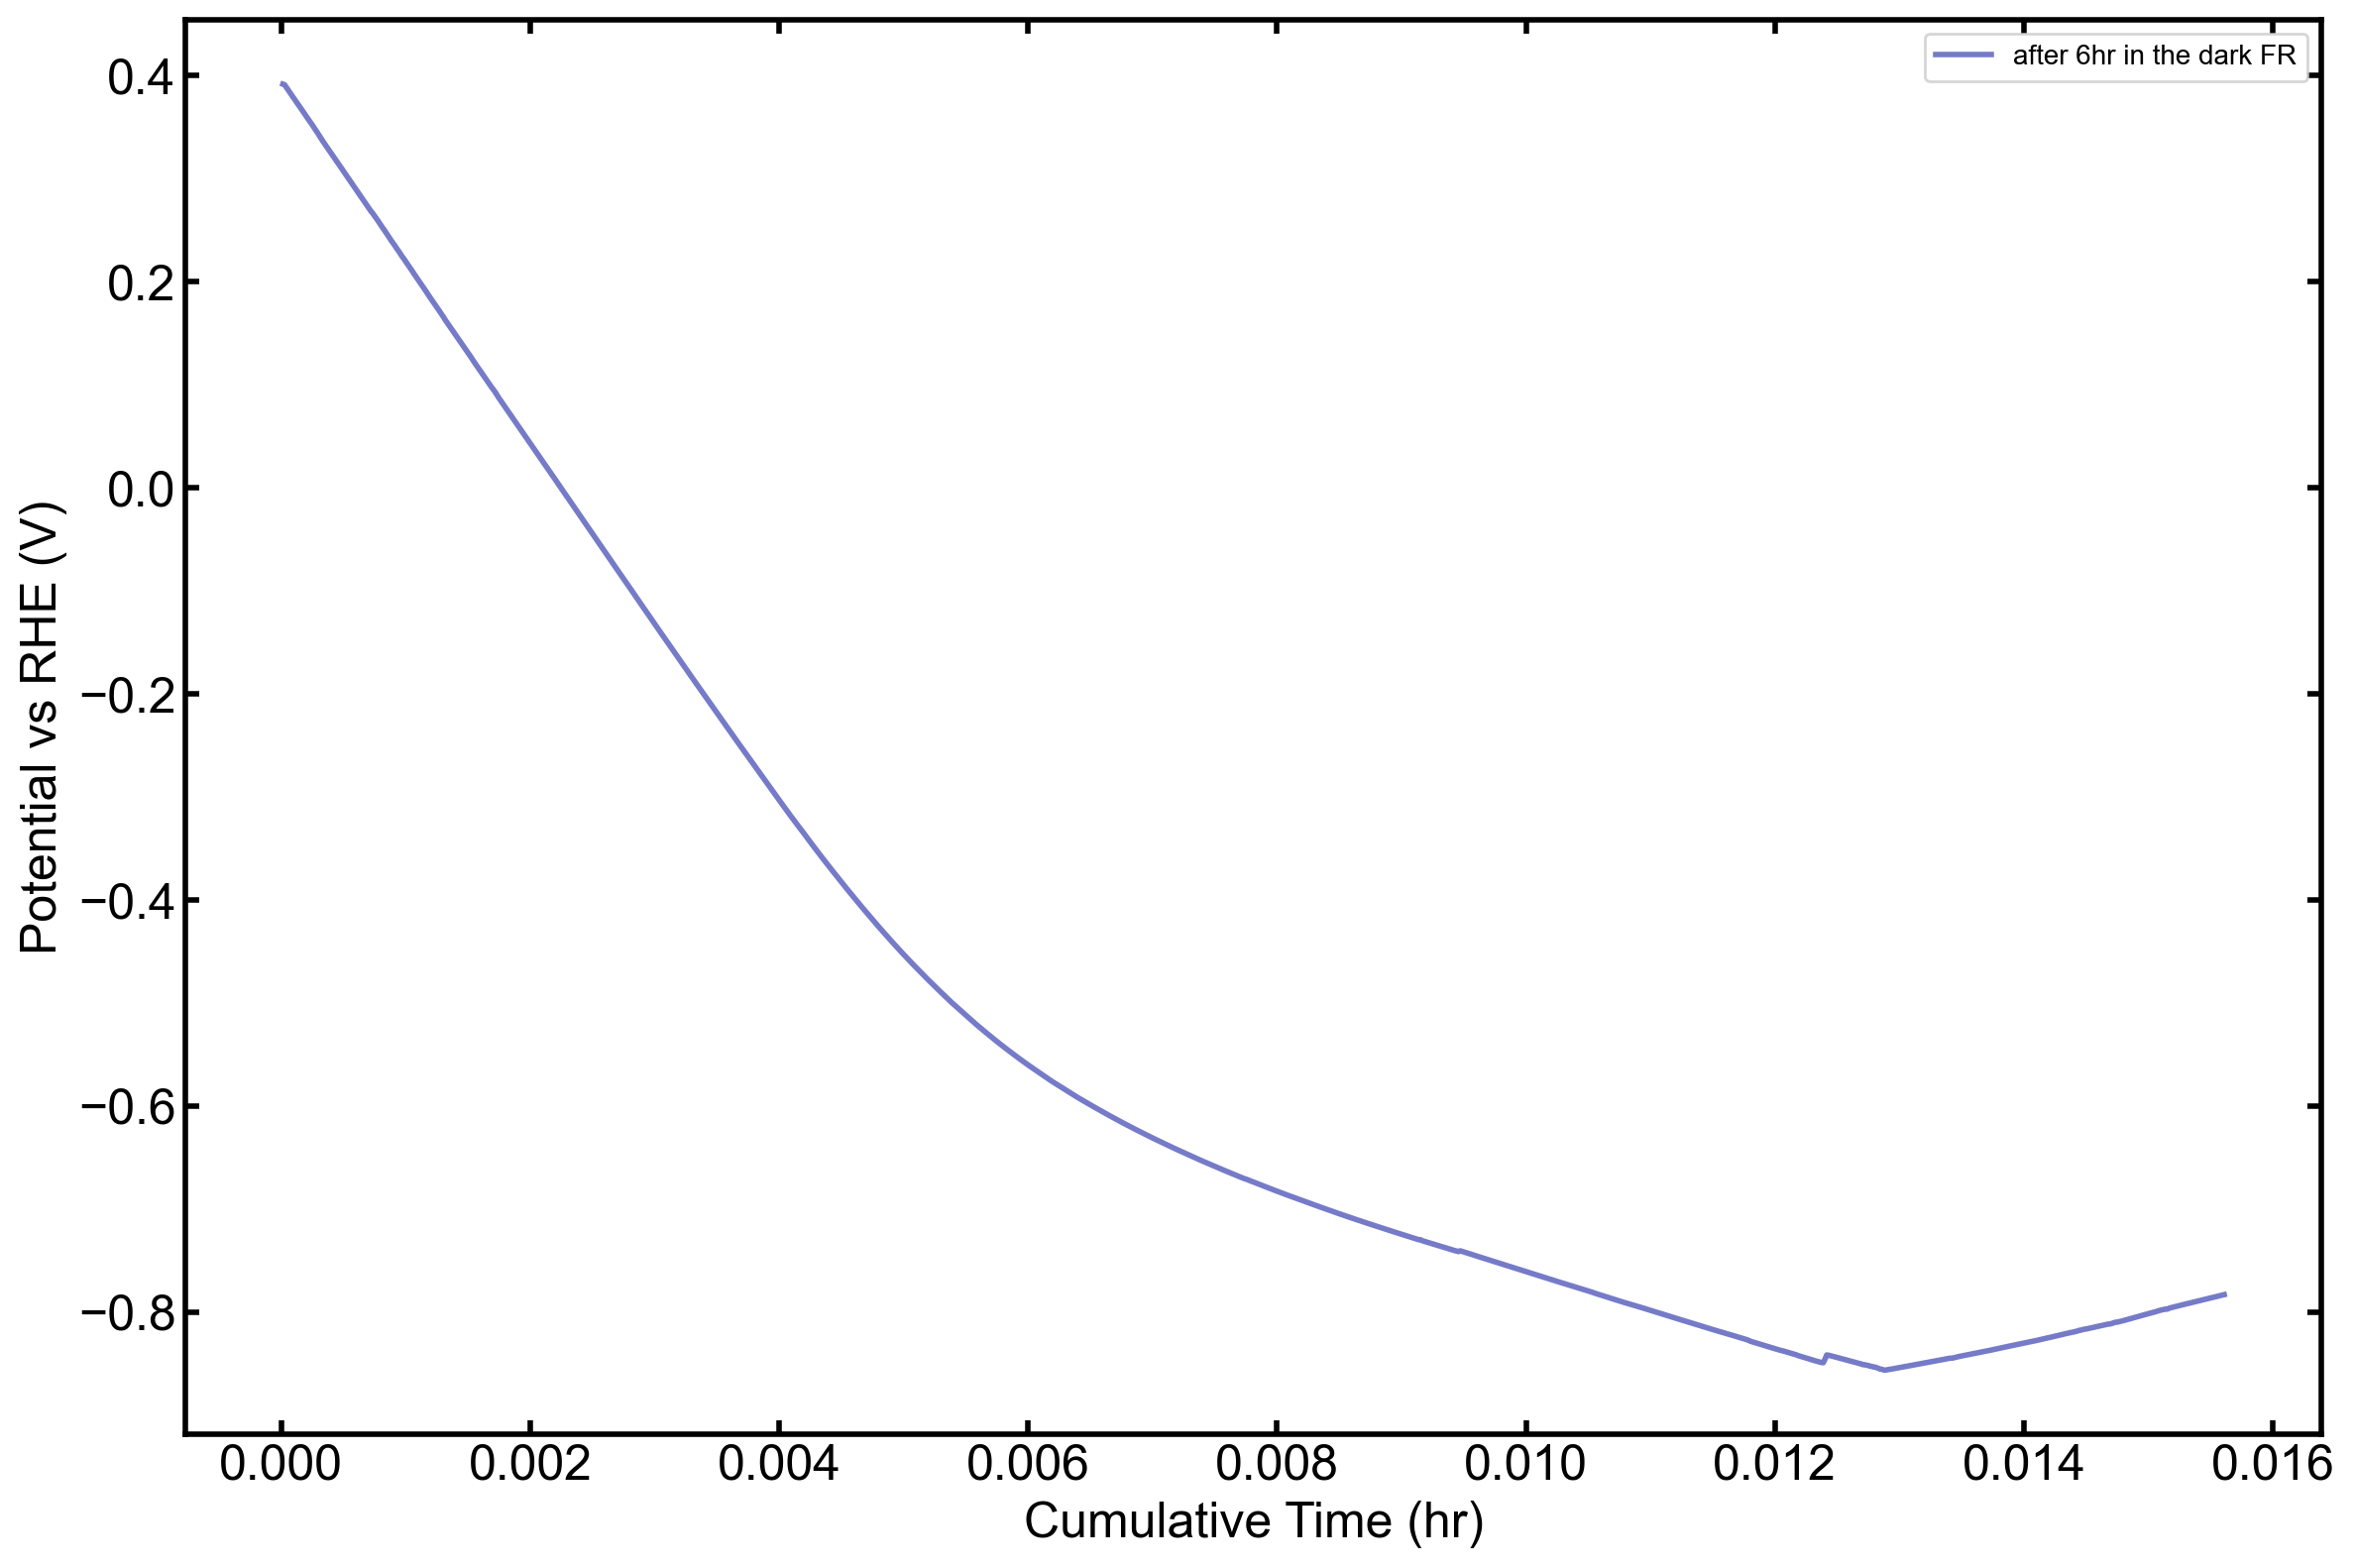

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import os

def find_skiprows(filename, encoding="ISO-8859-1"):
    """
    Find the number of rows to skip by locating the header line.
    The header line is assumed to contain 'time/s' and '<Ewe/V>'.
    """
    with open(filename, 'r', encoding=encoding) as f:
        for i, line in enumerate(f):
            if 'time/s' in line and '<Ewe/V>' in line:
                return i
    return 0 # Default to 0 if header not found

# --- File List & Parameters ---
# IMPORTANT: Make sure these files exist in the same directory as the script,
# or provide the full path to them.
filelist0p1sun = [
    '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p1sun_2_C01.mpt',
    '20260806_MW736n1_roncu_zonau_squaremask_10mlmin_co2flow_0p1sun_2_C02.mpt',
]

VALID_VOLTAGE_MIN = -10.0
VALID_VOLTAGE_MAX = 2.0
ref = 0.197
pH = 6.8
refi = ref + 0.059 * pH
cmap = ["#dab6fc", "#757bc8"]
plot_labels = ['initial FR', 'after 6hr in the dark FR']

# --- Plotting Setup ---
plt.figure(figsize=(12, 8))
plt.grid(False)
print(f"Filtering out data points outside the range: {VALID_VOLTAGE_MIN}V to {VALID_VOLTAGE_MAX}V")

# --- Plotting Loop ---
cumulative_time_offset = 0.0
for jj, filepath in enumerate(filelist0p1sun):
    if not os.path.exists(filepath):
        print(f"Error: The file '{filepath}' was not found. Skipping.")
        continue

    # Dynamically find the number of rows to skip
    skip = find_skiprows(filepath)
    print(f"Reading file '{filepath}', skipping {skip} header lines.")

    # Read data and filter
    try:
        df = pd.read_csv(filepath, skiprows=skip, encoding="ISO-8859-1", delimiter='\t', engine='python')
        
        # Defensive check for required columns
        if '<Ewe/V>' not in df.columns or 'time/s' not in df.columns:
            print(f"Warning: Missing required columns in '{filepath}'. Skipping.")
            continue

        df_filtered = df[(df['<Ewe/V>'] >= VALID_VOLTAGE_MIN) & (df['<Ewe/V>'] <= VALID_VOLTAGE_MAX)].copy()

        if not df_filtered.empty:
            # Calculate time for plotting
            df_filtered['plot_time_hr'] = (df_filtered['time/s'] / 3600) + cumulative_time_offset
            
            # Plot data
            current_label = plot_labels[jj] if jj < len(plot_labels) else f'File {jj+1}'
            plt.plot(df_filtered['plot_time_hr'], df_filtered['<Ewe/V>'] + refi - 0.09, color=cmap[jj % len(cmap)], linewidth=2.0, label=current_label)
            
            # Update time offset for the next file
            cumulative_time_offset = df_filtered['plot_time_hr'].max()
        else:
            print(f"Warning: No data left in '{filepath}' after filtering. Check voltage range and file content.")
            
    except Exception as e:
        print(f"An error occurred while processing '{filepath}': {e}")


# --- Formatting ---
plt.tick_params(axis='both', right=True, top=True, direction='in', width=2, length=5)
ax = plt.gca()
ax.spines['left'].set_linewidth(2)
ax.spines['top'].set_linewidth(2)
ax.spines['right'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)
plt.xlabel('Cumulative Time (hr)', fontsize=18)
plt.ylabel('Potential vs RHE (V)', fontsize=18)
plt.yticks(fontsize=18)
plt.xticks(fontsize=18)
plt.legend()
plt.tight_layout()
#plt.ylim(-0.65, -0.6)

# Save the figure and show the plot
plt.savefig("zoomed_voltage_after_ocv.pdf", format="pdf", bbox_inches="tight")
plt.show()
